# Pengaruh embedding & reasoning model terhadap kualitas jawaban

Notebook ini membaca langsung dari tabel `answer_result` (dan `question` untuk
label jawaban yang benar) di PostgreSQL - lihat `sql/create_table.sql` untuk
skema lengkapnya. Semua analisis berikut dipecah per metode retrieval
(`agent`, `pgvector`, `neo4j`):

1. Pengaruh embedding model terhadap accuracy/precision/recall/F1, dengan
   reasoning model dikunci ke `gpt-oss-120b` - hanya soal yes/no. Baris yang
   error (`is_correct` `NULL`) dihitung sebagai jawaban salah.
2. Pengaruh reasoning model terhadap accuracy/precision/recall/F1, dengan
   embedding model dikunci ke `qwen06b` - hanya soal yes/no, dengan aturan
   error yang sama.
3. Token usage per metode, dari seluruh baris `answer_result` (bukan cuma
   yes/no).
4. Hubungan `confidence` model dengan ketepatan jawaban (`is_correct`) untuk
   soal yes/no, per metode.


In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2
from dotenv import load_dotenv
from sklearn.metrics import precision_recall_fscore_support

REPO_ROOT = Path.cwd().parent
load_dotenv(REPO_ROOT / ".env")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.size": 10.5,
})

# Fixed hue per method, used consistently across every chart in this notebook.
METHOD_ORDER = ["agent", "pgvector", "neo4j"]
METHOD_COLOR = {
    "agent": "#2a78d6",
    "pgvector": "#eb6834",
    "neo4j": "#1baf7a",
}


def connect():
    conn_str = os.getenv("PG_CONNECTION_STRING")
    if conn_str:
        return psycopg2.connect(conn_str)
    return psycopg2.connect(host="localhost", dbname="docs", user="postgres", password="password")


## Memuat data

In [2]:
query = """
    SELECT
        ar.method,
        ar.embedding_model,
        ar.llm_reasoning_model,
        ar.is_correct,
        ar.confidence,
        ar.token_usage,
        q.answer
    FROM answer_result ar
    JOIN question q ON q.id = ar.question_id
"""
with connect() as conn:
    df = pd.read_sql(query, conn)

print(f"{len(df)} baris answer_result dimuat")
df.head()


6008 baris answer_result dimuat


/var/folders/6s/4n20n38x5y571387phy8c5lc0000gn/T/ipykernel_10881/2050680709.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,method,embedding_model,llm_reasoning_model,is_correct,confidence,token_usage,answer
0,agent,bge-m3,gpt-oss-120b,True,high,5373,0.0
1,agent,bge-m3,gpt-oss-120b,True,high,5305,1.0
2,agent,bge-m3,gpt-oss-120b,True,high,12374,1.0
3,neo4j,qwen06b,gemma-4-26b-a4b-it,True,high,31397,1.0
4,agent,qwen06b,gpt-oss-120b,True,high,14541,1.0


Soal yes/no ditandai oleh `question.answer IS NOT NULL` (soal open-ended
tidak pernah punya jawaban biner sehingga `answer` selalu `NULL`). Dari situ,
jawaban model ("predicted") bisa direkonstruksi tanpa parsing teks bebas:
kalau jawabannya benar, `predicted == answer`; kalau salah, `predicted`
adalah kebalikan dari `answer`.

Beberapa baris yes/no punya `is_correct` `NULL` - ini bukan soal yang tidak
discore, tapi panggilan yang gagal/error (`result` kosong, biasanya dari
method `agent`/`neo4j`). Baris-baris ini diperlakukan sebagai **salah**,
bukan dibuang, supaya kegagalan tiap metode ikut tercermin di metriknya.

In [3]:
yes_no = df[df["answer"].notna()].copy()
yes_no["answer"] = yes_no["answer"].astype(int)
yes_no["is_correct"] = yes_no["is_correct"].fillna(False)
yes_no["predicted"] = np.where(yes_no["is_correct"], yes_no["answer"], 1 - yes_no["answer"])

n_errors = (df["answer"].notna() & df["is_correct"].isna()).sum()
print(f"{len(yes_no)} baris soal yes/no (dari total {len(df)} baris), termasuk {n_errors} baris error/null dianggap salah")


def compute_metrics(group: pd.DataFrame) -> pd.Series:
    precision, recall, f1, _ = precision_recall_fscore_support(
        group["answer"], group["predicted"], average="binary", pos_label=1, zero_division=0
    )
    return pd.Series({
        "accuracy": group["is_correct"].mean(),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "n": len(group),
    })


def plot_metric_grid(metrics_df, category_col, category_order, title):
    """2x2 grid (accuracy/precision/recall/F1), grouped bars colored by method."""
    metric_names = ["accuracy", "precision", "recall", "f1"]
    x = np.arange(len(category_order))
    bar_width = 0.25

    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharey=True)
    for ax, metric in zip(axes.flat, metric_names):
        for i, method in enumerate(METHOD_ORDER):
            sub = metrics_df[metrics_df["method"] == method].set_index(category_col)
            values = [sub.loc[c, metric] if c in sub.index else np.nan for c in category_order]
            ax.bar(
                x + (i - 1) * bar_width, values, width=bar_width,
                label=method, color=METHOD_COLOR[method], zorder=3,
            )
        ax.set_title(metric.capitalize(), fontsize=11)
        ax.set_xticks(x)
        ax.set_xticklabels(category_order, rotation=20, ha="right")
        ax.set_ylim(0, 1)
        ax.grid(axis="y", color="#e5e5e2", linewidth=0.8, zorder=0)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04), frameon=False)
    fig.suptitle(title, y=1.1, fontsize=13)
    fig.tight_layout()
    plt.show()


3609 baris soal yes/no (dari total 6008 baris), termasuk 27 baris error/null dianggap salah


## 1. Pengaruh embedding model

Reasoning model dikunci ke `gpt-oss-120b`.

In [4]:
EMBED_ORDER = ["minilml12", "bge-m3", "qwen06b", "qwen4b", "qwen8b"]  # urut dari model terkecil ke terbesar

embed_df = yes_no[yes_no["llm_reasoning_model"] == "gpt-oss-120b"]
embed_metrics = (
    embed_df.groupby(["embedding_model", "method"])
    .apply(compute_metrics, include_groups=False)
    .reset_index()
)
embed_metrics.pivot(index="embedding_model", columns="method", values=["accuracy", "precision", "recall", "f1", "n"]).reindex(EMBED_ORDER)


accuracy                     precision                      \
method              agent     neo4j  pgvector     agent     neo4j  pgvector   
embedding_model                                                               
minilml12        0.862745  0.830065  0.934641  0.873239  0.815789  0.890244   
bge-m3           0.823529  0.777778  0.921569  0.850746  0.770270  0.878049   
qwen06b          0.895425  0.862745  0.941176  0.862500  0.863014  0.891566   
qwen4b           0.856209  0.836601  0.928105  0.851351  0.835616  0.888889   
qwen8b           0.830065  0.856209  0.947712  0.800000  0.871429  0.912500   

                   recall                            f1                      \
method              agent     neo4j  pgvector     agent     neo4j  pgvector   
embedding_model                                                               
minilml12        0.837838  0.837838  0.986486  0.855172  0.826667  0.935897   
bge-m3           0.770270  0.770270  0.972973  0.808511  0.770270  0.923077   
qwen06b          0.932432  0.851351  1.000000  0.896104  0.857143  0.942675   
qwen4b           0.851351  0.824324  0.972973  0.851351  0.829932  0.929032   
qwen8b           0.864865  0.824324  0.986486  0.831169  0.847222  0.948052   

                     n                  
method           agent  neo4j pgvector  
embedding_model                         
minilml12        153.0  153.0    153.0  
bge-m3           153.0  153.0    153.0  
qwen06b          153.0  153.0    153.0  
qwen4b           153.0  153.0    153.0  
qwen8b           153.0  153.0    153.0

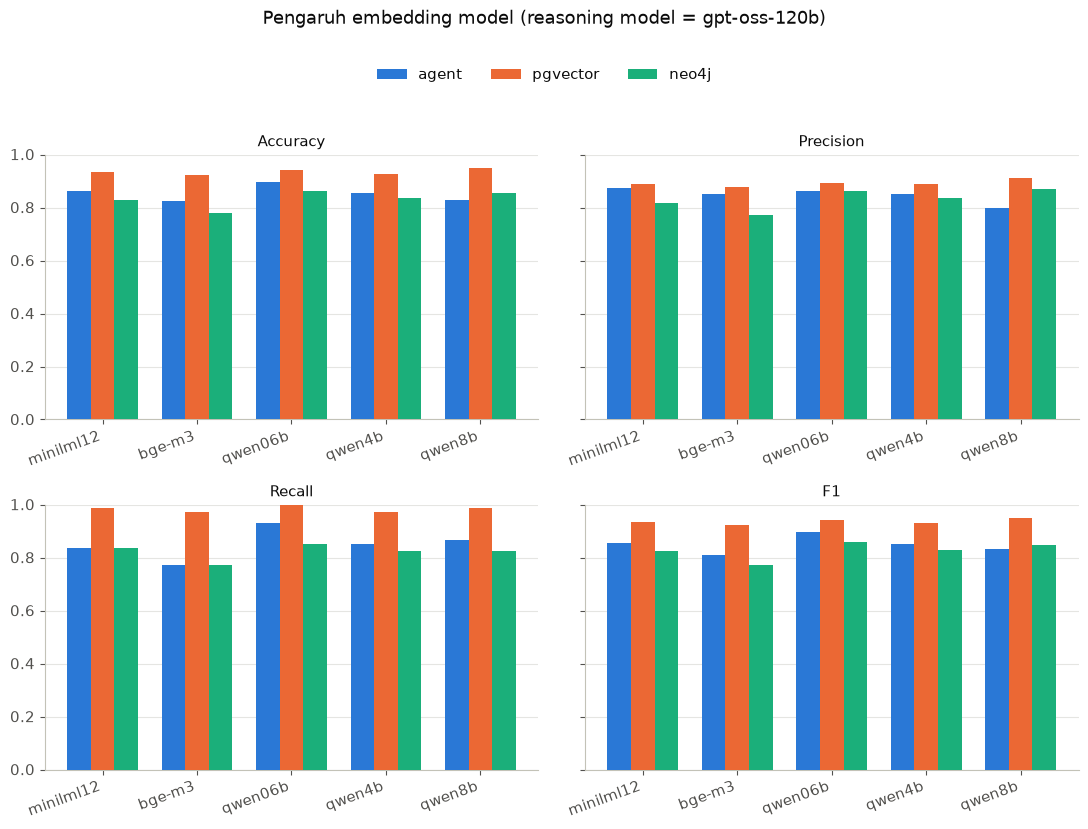

In [5]:
plot_metric_grid(
    embed_metrics, "embedding_model", EMBED_ORDER,
    "Pengaruh embedding model (reasoning model = gpt-oss-120b)",
)


## 2. Pengaruh reasoning model

Embedding model dikunci ke `qwen06b`.

In [6]:
REASON_ORDER = sorted(yes_no.loc[yes_no["embedding_model"] == "qwen06b", "llm_reasoning_model"].unique())

reason_df = yes_no[yes_no["embedding_model"] == "qwen06b"]
reason_metrics = (
    reason_df.groupby(["llm_reasoning_model", "method"])
    .apply(compute_metrics, include_groups=False)
    .reset_index()
)
reason_metrics.pivot(index="llm_reasoning_model", columns="method", values=["accuracy", "precision", "recall", "f1", "n"]).reindex(REASON_ORDER)


accuracy                     precision            \
method                     agent     neo4j  pgvector     agent     neo4j   
llm_reasoning_model                                                        
deepseek-v4.1-flash     0.954248  0.973856  0.980392  0.958904  0.972973   
gemma-4-26b-a4b-it      0.900000  0.941176  0.973856  0.937500  0.957746   
gpt-oss-120b            0.895425  0.862745  0.941176  0.862500  0.863014   
llama-3.3-70b-instruct  0.745098  0.823529  0.960784  0.701149  0.783133   

                                    recall                            f1  \
method                  pgvector     agent     neo4j  pgvector     agent   
llm_reasoning_model                                                        
deepseek-v4.1-flash     0.973333  0.945946  0.972973  0.986486  0.952381   
gemma-4-26b-a4b-it      0.972973  0.810811  0.918919  0.972973  0.869565   
gpt-oss-120b            0.891566  0.932432  0.851351  1.000000  0.896104   
llama-3.3-70b-instruct  0.935897  0.824324  0.878378  0.986486  0.757764   

                                                n                  
method                     neo4j  pgvector  agent  neo4j pgvector  
llm_reasoning_model                                                
deepseek-v4.1-flash     0.972973  0.979866  153.0  153.0    153.0  
gemma-4-26b-a4b-it      0.937931  0.972973   90.0  153.0    153.0  
gpt-oss-120b            0.857143  0.942675  153.0  153.0    153.0  
llama-3.3-70b-instruct  0.828025  0.960526  153.0  153.0    153.0

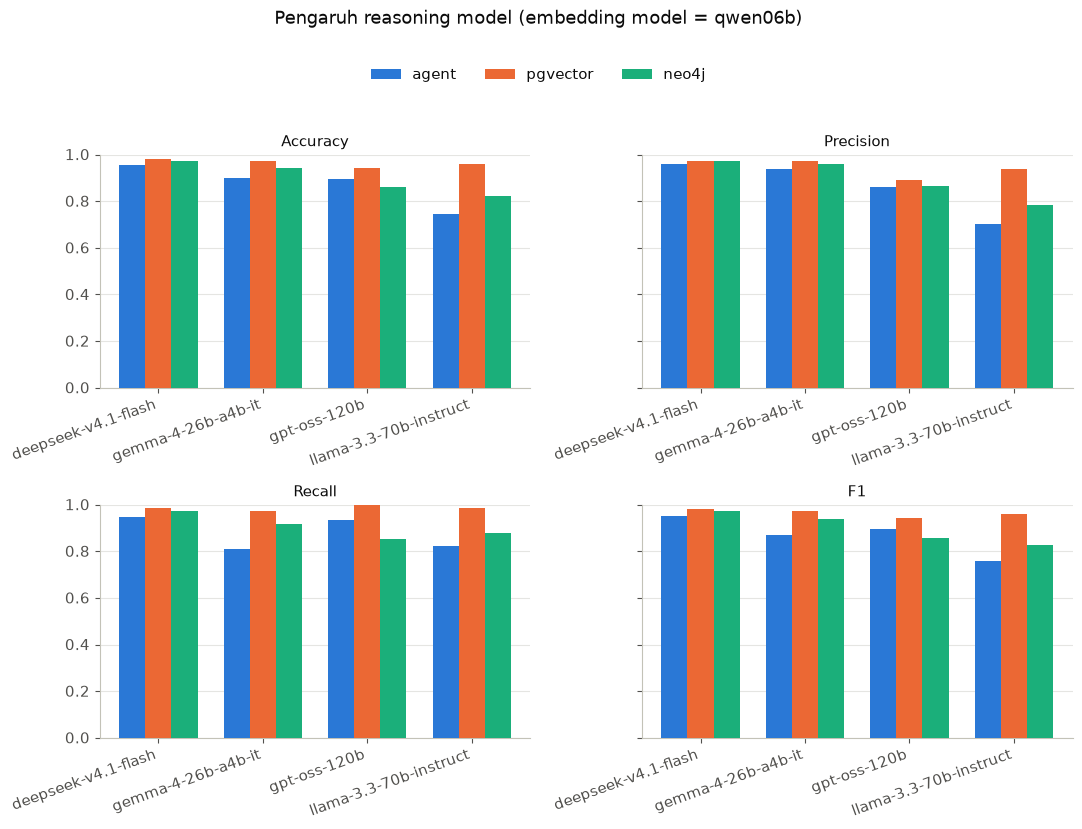

In [7]:
plot_metric_grid(
    reason_metrics, "llm_reasoning_model", REASON_ORDER,
    "Pengaruh reasoning model (embedding model = qwen06b)",
)


## 3. Token usage per metode

Memakai seluruh baris `answer_result` (yes/no maupun open-ended), bukan hanya
yang punya `is_correct`.

Distribusinya sangat right-skewed (ada outlier sampai jutaan token), jadi
mean/std kurang representatif - dipakai median +- IQR untuk ringkasannya, dan
skala log untuk melihat sebaran penuhnya.

In [8]:
token_stats = (
    df.groupby("method")["token_usage"]
    .agg(
        mean="mean",
        median="median",
        p25=lambda s: s.quantile(0.25),
        p75=lambda s: s.quantile(0.75),
        total="sum",
        n="count",
    )
    .reindex(METHOD_ORDER)
)
token_stats


,mean,median,p25,p75,total,n
method,,,,,,
agent,66918.120408,18835.5,6847.25,86877.75,131159516,1960
pgvector,1073.875988,1065.0,966.00,1239.00,2173525,2024
neo4j,50787.743577,8707.0,2745.25,47370.00,102794393,2024


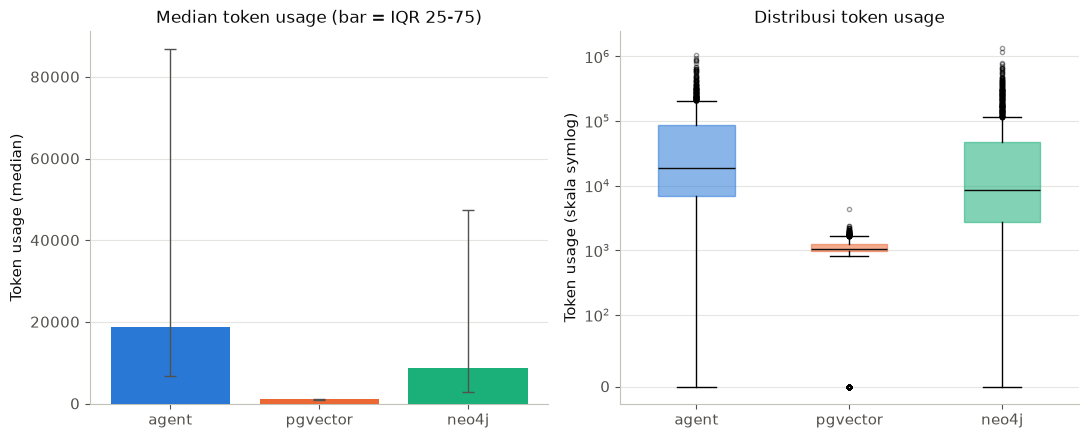

In [9]:
fig, (ax_bar, ax_box) = plt.subplots(1, 2, figsize=(11, 4.5))

x = np.arange(len(METHOD_ORDER))
medians = token_stats["median"].to_numpy()
lower_err = medians - token_stats["p25"].to_numpy()
upper_err = token_stats["p75"].to_numpy() - medians
colors = [METHOD_COLOR[m] for m in METHOD_ORDER]

ax_bar.bar(x, medians, yerr=[lower_err, upper_err], capsize=4, color=colors, zorder=3,
           error_kw={"ecolor": "#52514e", "elinewidth": 1})
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(METHOD_ORDER)
ax_bar.set_ylabel("Token usage (median)")
ax_bar.set_title("Median token usage (bar = IQR 25-75)")
ax_bar.grid(axis="y", color="#e5e5e2", linewidth=0.8, zorder=0)
ax_bar.set_axisbelow(True)
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)

box_data = [df.loc[df["method"] == m, "token_usage"].dropna() for m in METHOD_ORDER]
bp = ax_box.boxplot(box_data, tick_labels=METHOD_ORDER, patch_artist=True, widths=0.5,
                     medianprops={"color": "#0b0b0b"}, flierprops={"markersize": 3, "alpha": 0.4})
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.55)
    patch.set_edgecolor(color)
ax_box.set_yscale("symlog", linthresh=100)
ax_box.set_ylabel("Token usage (skala symlog)")
ax_box.set_title("Distribusi token usage")
ax_box.grid(axis="y", color="#e5e5e2", linewidth=0.8, zorder=0)
ax_box.set_axisbelow(True)
ax_box.spines["top"].set_visible(False)
ax_box.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()


## 4. Confidence vs ketepatan jawaban

Hanya soal yes/no, dan hanya baris yang punya `confidence` (ada beberapa baris
lama tanpa nilai ini).

In [10]:
CONF_ORDER = ["low", "medium", "high"]

conf_df = yes_no[yes_no["confidence"].notna()]
conf_stats = (
    conf_df.groupby(["method", "confidence"])
    .agg(accuracy=("is_correct", "mean"), n=("is_correct", "size"))
    .reset_index()
)
conf_stats.pivot(index="confidence", columns="method", values=["accuracy", "n"]).reindex(CONF_ORDER)


accuracy                         n               
method         agent     neo4j  pgvector agent neo4j pgvector
confidence                                                   
low          0.70098  0.734694  0.958763   204   196       97
medium      0.823529   0.78169  0.871429   102   142       70
high        0.906619  0.922811  0.952696   846   868     1057

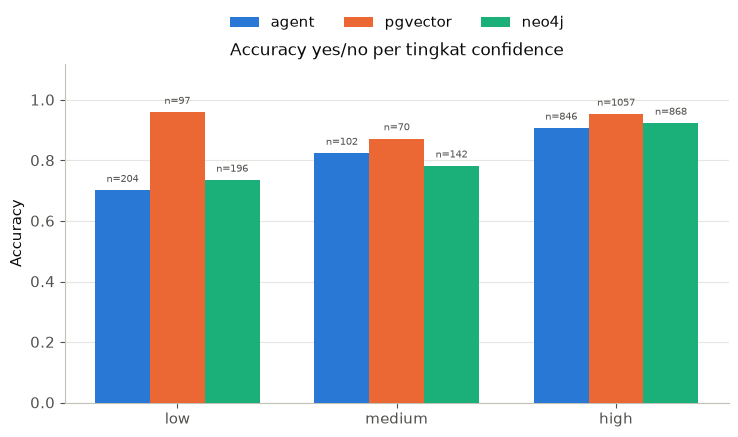

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))

x = np.arange(len(CONF_ORDER))
bar_width = 0.25
for i, method in enumerate(METHOD_ORDER):
    sub = conf_stats[conf_stats["method"] == method].set_index("confidence")
    values = [sub.loc[c, "accuracy"] if c in sub.index else np.nan for c in CONF_ORDER]
    counts = [int(sub.loc[c, "n"]) if c in sub.index else 0 for c in CONF_ORDER]
    bars = ax.bar(x + (i - 1) * bar_width, values, width=bar_width,
                  label=method, color=METHOD_COLOR[method], zorder=3)
    for bar, n in zip(bars, counts):
        if n:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f"n={n}",
                    ha="center", va="bottom", fontsize=7.5, color="#52514e")

ax.set_xticks(x)
ax.set_xticklabels(CONF_ORDER)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy yes/no per tingkat confidence")
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.18), frameon=False)

fig.tight_layout()
plt.show()
